In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
#%load_ext line_profiler
#%load_ext snakeviz
%autoreload 2


import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import corner

import pickle

import enterprise
from enterprise.pulsar import Pulsar
import enterprise.signals.parameter as parameter
from enterprise.signals import utils
from enterprise.signals import signal_base
from enterprise.signals import selections
from enterprise.signals.selections import Selection
from enterprise.signals import white_signals
from enterprise.signals import gp_signals
from enterprise.signals import deterministic_signals
import enterprise.constants as const

from enterprise_extensions import deterministic

from scipy.stats import norm

import libstempo as T2
import libstempo.toasim as LT
import libstempo.plot as LP

import glob
import json
import h5py
import healpy as hp
import scipy.constants as sc
import emcee

from numba.typed import List

import sys
import h5py
import os

In [2]:
target_d_L = 317.7#Mpc

In [3]:
filename = "3C66B_detect_corner_plot.pdf"

In [4]:
base = "3C66B_narrow_detection_dL_93.6"
crnr_plt_title1 =base
crnr_plt_title2 =base+'_corner plot_all_params'
trace_plot_title = base+'trace_plot'
BF_histogram_title = base+'log10A_histogram'
BFerr_title = base+'log10A_histogram_error'

In [5]:
pwd

'/scratch/na00078/projects/eccentric_QuickCW/post_processing/detection'

## Generate Outfile

## Run Outfile

In [6]:
import h5py

# --- Configuration ---
infile = "/scratch/na00078/projects/eccentric_QuickCW/h5_files/3C66B_detect.h5"
first_n_param = 8
# outfile = '/scratch/na00078/QuickCW_targeted_runs/results/3C66B_outfile.h5'  # COMMENT IF OUTFILE GENERATED

print(f"Input file: {infile}")
print(f"Number of parameters to load: {first_n_param}")

# --- Load data ---
with h5py.File(infile, 'r') as f:
    Ts = f['T-ladder'][...]
    samples_cold = f['samples_cold'][:, :, :first_n_param]
    log_likelihood = f['log_likelihood'][:1, :]
    par_names = [x.decode('UTF-8') for x in f['par_names'][...]]
    acc_fraction = f['acc_fraction'][...]
    fisher_diag = f['fisher_diag'][...]

# --- Print summaries ---
print("\n--- File Summary ---")
print(f"T-ladder shape: {Ts.shape}")
print(f"samples_cold shape: {samples_cold.shape}")
print(f"log_likelihood shape: {log_likelihood.shape}")
print(f"acc_fraction shape: {acc_fraction.shape}")
print(f"fisher_diag shape: {fisher_diag.shape}")

print("\n--- Parameter Names ---")
for i, name in enumerate(par_names):
    print(f"{i}: {name}")


Input file: /scratch/na00078/projects/eccentric_QuickCW/h5_files/3C66B_detect.h5
Number of parameters to load: 8

--- File Summary ---
T-ladder shape: (4,)
samples_cold shape: (1, 2770000, 8)
log_likelihood shape: (1, 2770000)
acc_fraction shape: (32, 4)
fisher_diag shape: (4, 278)

--- Parameter Names ---
0: 0_cos_gwtheta
1: 0_cos_inc
2: 0_gwphi
3: 0_log10_dist
4: 0_log10_fgw
5: 0_log10_mc
6: 0_phase0
7: 0_psi
8: B1855+09_cw0_p_dist
9: B1855+09_cw0_p_phase
10: B1855+09_red_noise_gamma
11: B1855+09_red_noise_log10_A
12: B1937+21_cw0_p_dist
13: B1937+21_cw0_p_phase
14: B1937+21_red_noise_gamma
15: B1937+21_red_noise_log10_A
16: B1953+29_cw0_p_dist
17: B1953+29_cw0_p_phase
18: B1953+29_red_noise_gamma
19: B1953+29_red_noise_log10_A
20: J0023+0923_cw0_p_dist
21: J0023+0923_cw0_p_phase
22: J0023+0923_red_noise_gamma
23: J0023+0923_red_noise_log10_A
24: J0030+0451_cw0_p_dist
25: J0030+0451_cw0_p_phase
26: J0030+0451_red_noise_gamma
27: J0030+0451_red_noise_log10_A
28: J0340+4130_cw0_p_dist


## Corner Plots

Loaded samples shape: (2770000, 8)


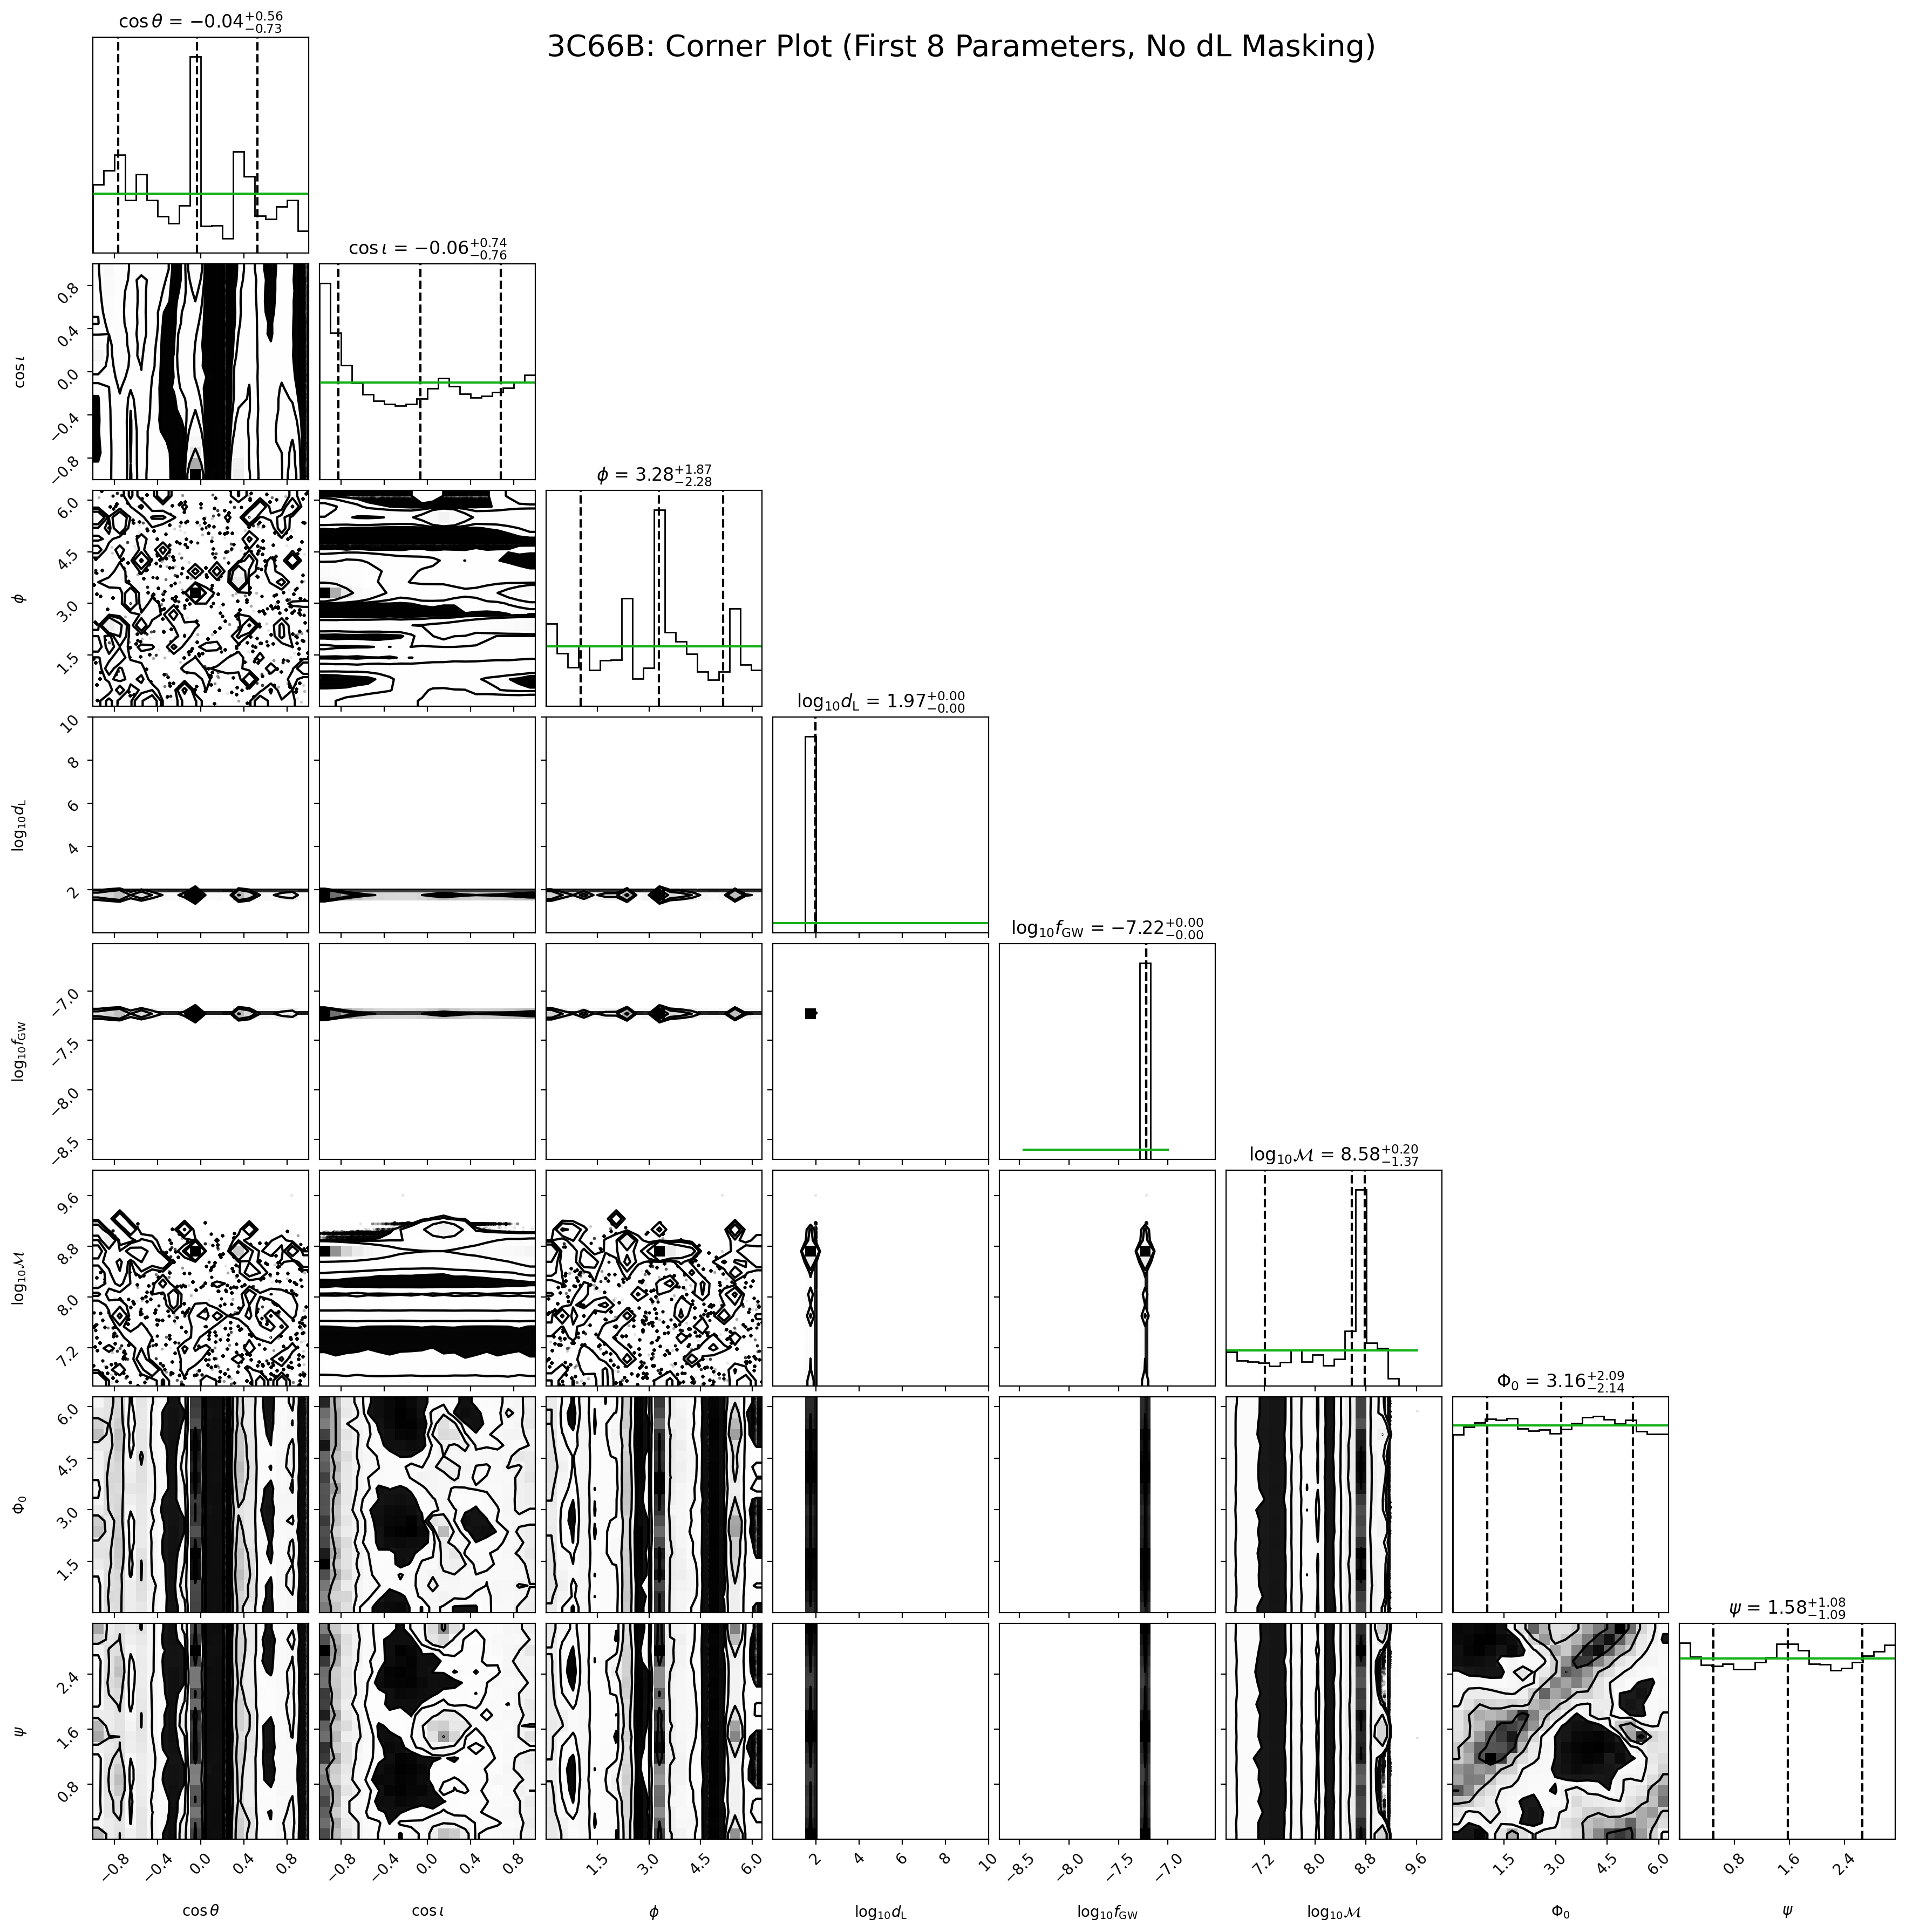

In [7]:
burnin = 0
thin = 1

# Use the coldest chain (T=0 index)
samples = samples_cold[0][burnin::thin, :first_n_param]
print(f"Loaded samples shape: {samples.shape}")

# ================== LABELS AND RANGES ================== #
labels = [
    r"$\cos \theta$", r"$\cos \iota$", r"$\phi$", r"$\log_{10} d_{\rm L}$", r"$\log_{10} f_{\rm GW}$",
    r"$\log_{10} {\cal M}$", r"$\Phi_0$", r"$\psi$"
]

ranges = [
    (-1, 1),             # cos θ
    (-1, 1),             # cos ι
    (0, 2*np.pi),        # φ
    (0, 10),          #dL
    (-8.704, np.log10(3e-7)),  # log10 fGW
    (6.6, 10),          # log10 M_c
    (0, 2*np.pi),        # Φ0
    (0, np.pi)           # ψ
]

# ================== CORNER PLOT ================== #
fig = corner.corner(
    samples,
    labels=labels,
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84],
    range=ranges,
    hist_kwargs={"density": True}
)

# ================== OVERLAY PRIORS ================== #
for i, ax in enumerate(fig.axes):
    if i == 0 or i == (len(labels)+1):  # cos inc and cos theta
        Xs = np.linspace(-1, 1)
        ax.plot(Xs, Xs*0 + 1/2, color="xkcd:green")
    elif i == 2*(len(labels)+1) or i == 6*(len(labels)+1):  # gwphi and phase0
        Xs = np.linspace(0, 2*np.pi)
        ax.plot(Xs, Xs*0 + 1/(2*np.pi), color="xkcd:green")
    elif i == 3*(len(labels)+1):  # dL prior
        Xs = np.linspace(0, 10)
        ax.plot(Xs, Xs*0 + 1/10, color="xkcd:green")
    elif i == 4*(len(labels)+1):  #log10_fgw
        Xs = np.linspace(np.log10(3.5e-9), -7.0)
        ax.plot(Xs, Xs*0 + 1/(np.log10(3e-7) + 8.704), color="xkcd:green")
    elif i == 5*(len(labels)+1):  # log10_M_ch
        Xs = np.linspace(np.min(samples[:, 5]), np.max(samples[:, 5]))
        ax.plot(Xs, Xs*0 + 1/3, color="xkcd:green")
    elif i == 7*(len(labels)+1):  # psi
        Xs = np.linspace(0, np.pi)
        ax.plot(Xs, Xs*0 + 1/np.pi, color="xkcd:green")

# ================== FINAL TOUCHES ================== #
fig.suptitle("3C66B: Corner Plot (First 8 Parameters, No dL Masking)", fontsize=20)
plt.show()

Loaded samples shape: (2770000, 8)


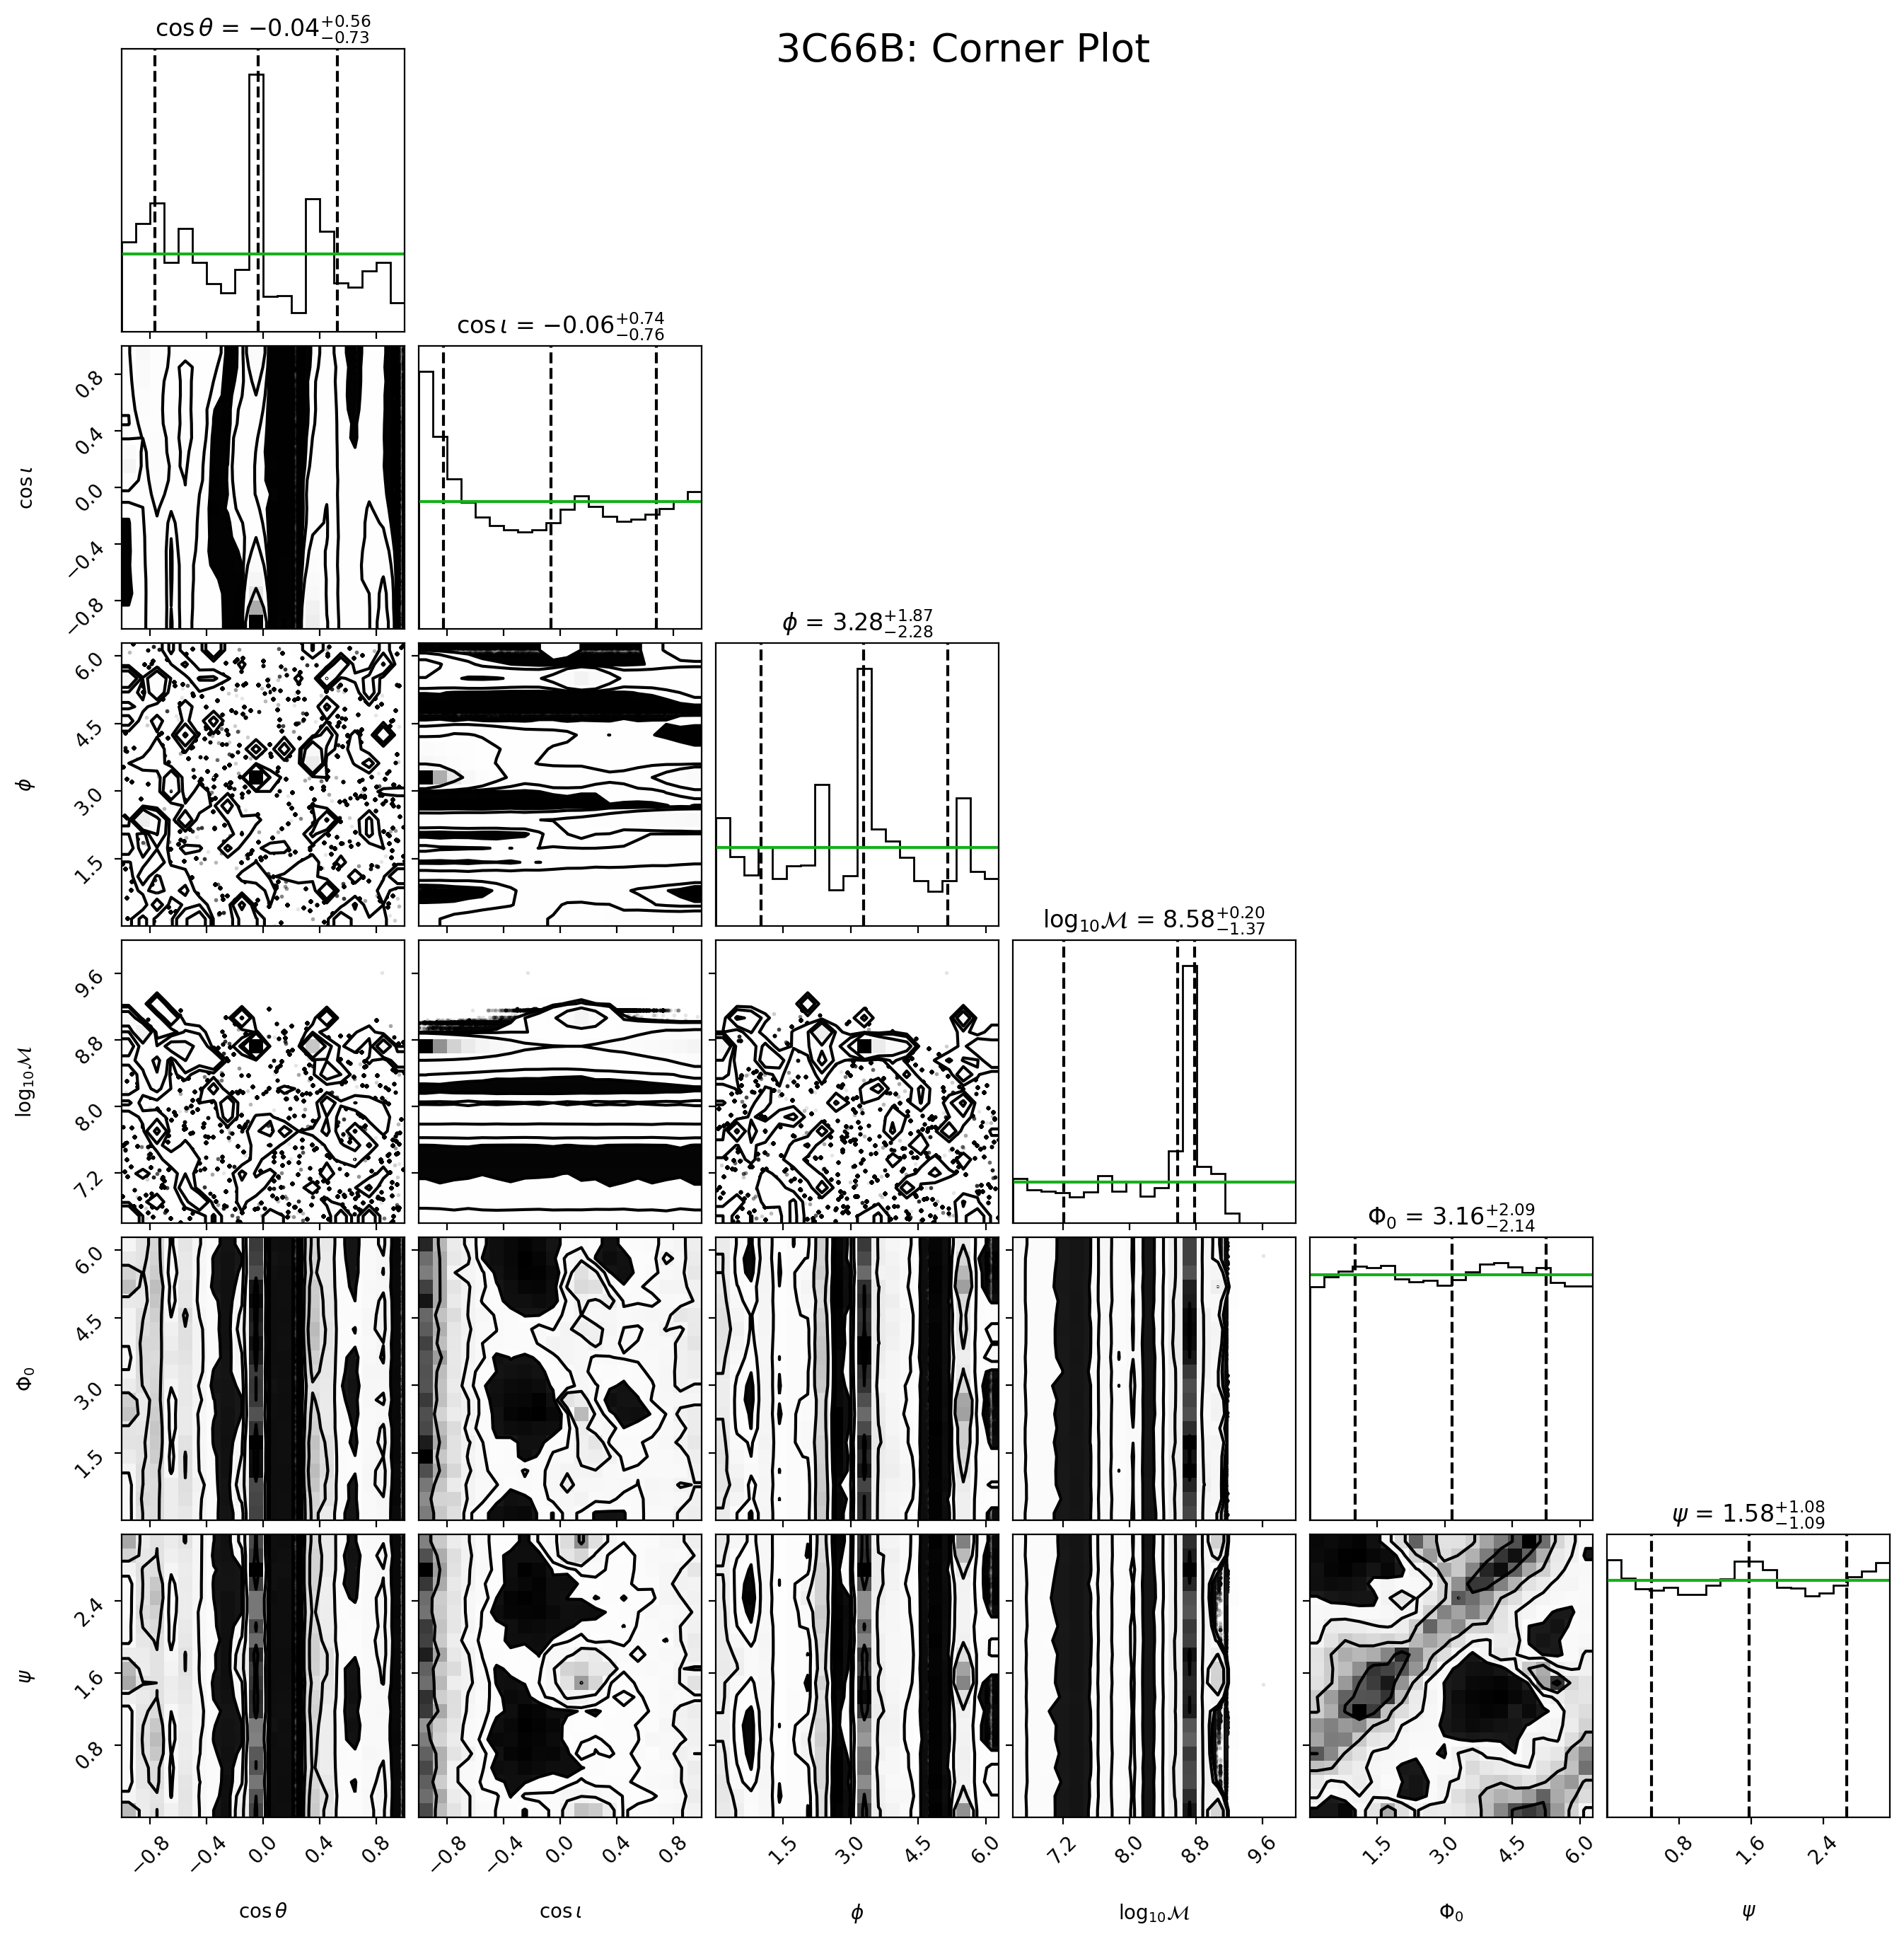

In [22]:
# ================== CONFIG ================== #
burnin = 0
thin = 1

# Use the coldest chain (T=0 index)
samples = samples_cold[0][burnin::thin, :first_n_param]
print(f"Loaded samples shape: {samples.shape}")

# Select only the parameters we want (excluding dL and fGW)
# Assuming the order is:
# 0_cos_gwtheta, 0_cos_inc, 0_gwphi, 0_log10_dL, 0_log10_fgw, 0_log10_mc, 0_phase0, 0_psi
selected_indices = [0, 1, 2, 5, 6, 7]
samples = samples[:, selected_indices]

# ================== LABELS AND RANGES ================== #
labels = [
    r"$\cos \theta$", 
    r"$\cos \iota$", 
    r"$\phi$", 
    r"$\log_{10} {\cal M}$", 
    r"$\Phi_0$", 
    r"$\psi$"
]

ranges = [
    (-1, 1),             # cos θ
    (-1, 1),             # cos ι
    (0, 2*np.pi),        # φ
    (6.6, 10),           # log10 M_c
    (0, 2*np.pi),        # Φ0
    (0, np.pi)           # ψ
]

# ================== CORNER PLOT ================== #
fig = corner.corner(
    samples,
    labels=labels,
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84],
    range=ranges,
    hist_kwargs={"density": True}
)

# ================== OVERLAY PRIORS ================== #
for i, ax in enumerate(fig.axes):
    if i == 0 or i == (len(labels)+1):  # cos θ and cos ι
        Xs = np.linspace(-1, 1)
        ax.plot(Xs, Xs*0 + 1/2, color="xkcd:green")
    elif i == 2*(len(labels)+1) or i == 4*(len(labels)+1):  # φ and Φ0
        Xs = np.linspace(0, 2*np.pi)
        ax.plot(Xs, Xs*0 + 1/(2*np.pi), color="xkcd:green")
    elif i == 3*(len(labels)+1):  # log10 M_c prior
        Xs = np.linspace(6.6, 10)
        ax.plot(Xs, Xs*0 + 1/(10 - 6.6), color="xkcd:green")
    elif i == 5*(len(labels)+1):  # ψ
        Xs = np.linspace(0, np.pi)
        ax.plot(Xs, Xs*0 + 1/np.pi, color="xkcd:green")

# ================== FINAL TOUCHES ================== #
fig.suptitle("3C66B: Corner Plot", fontsize=20)
plt.show()

## Trace Plots

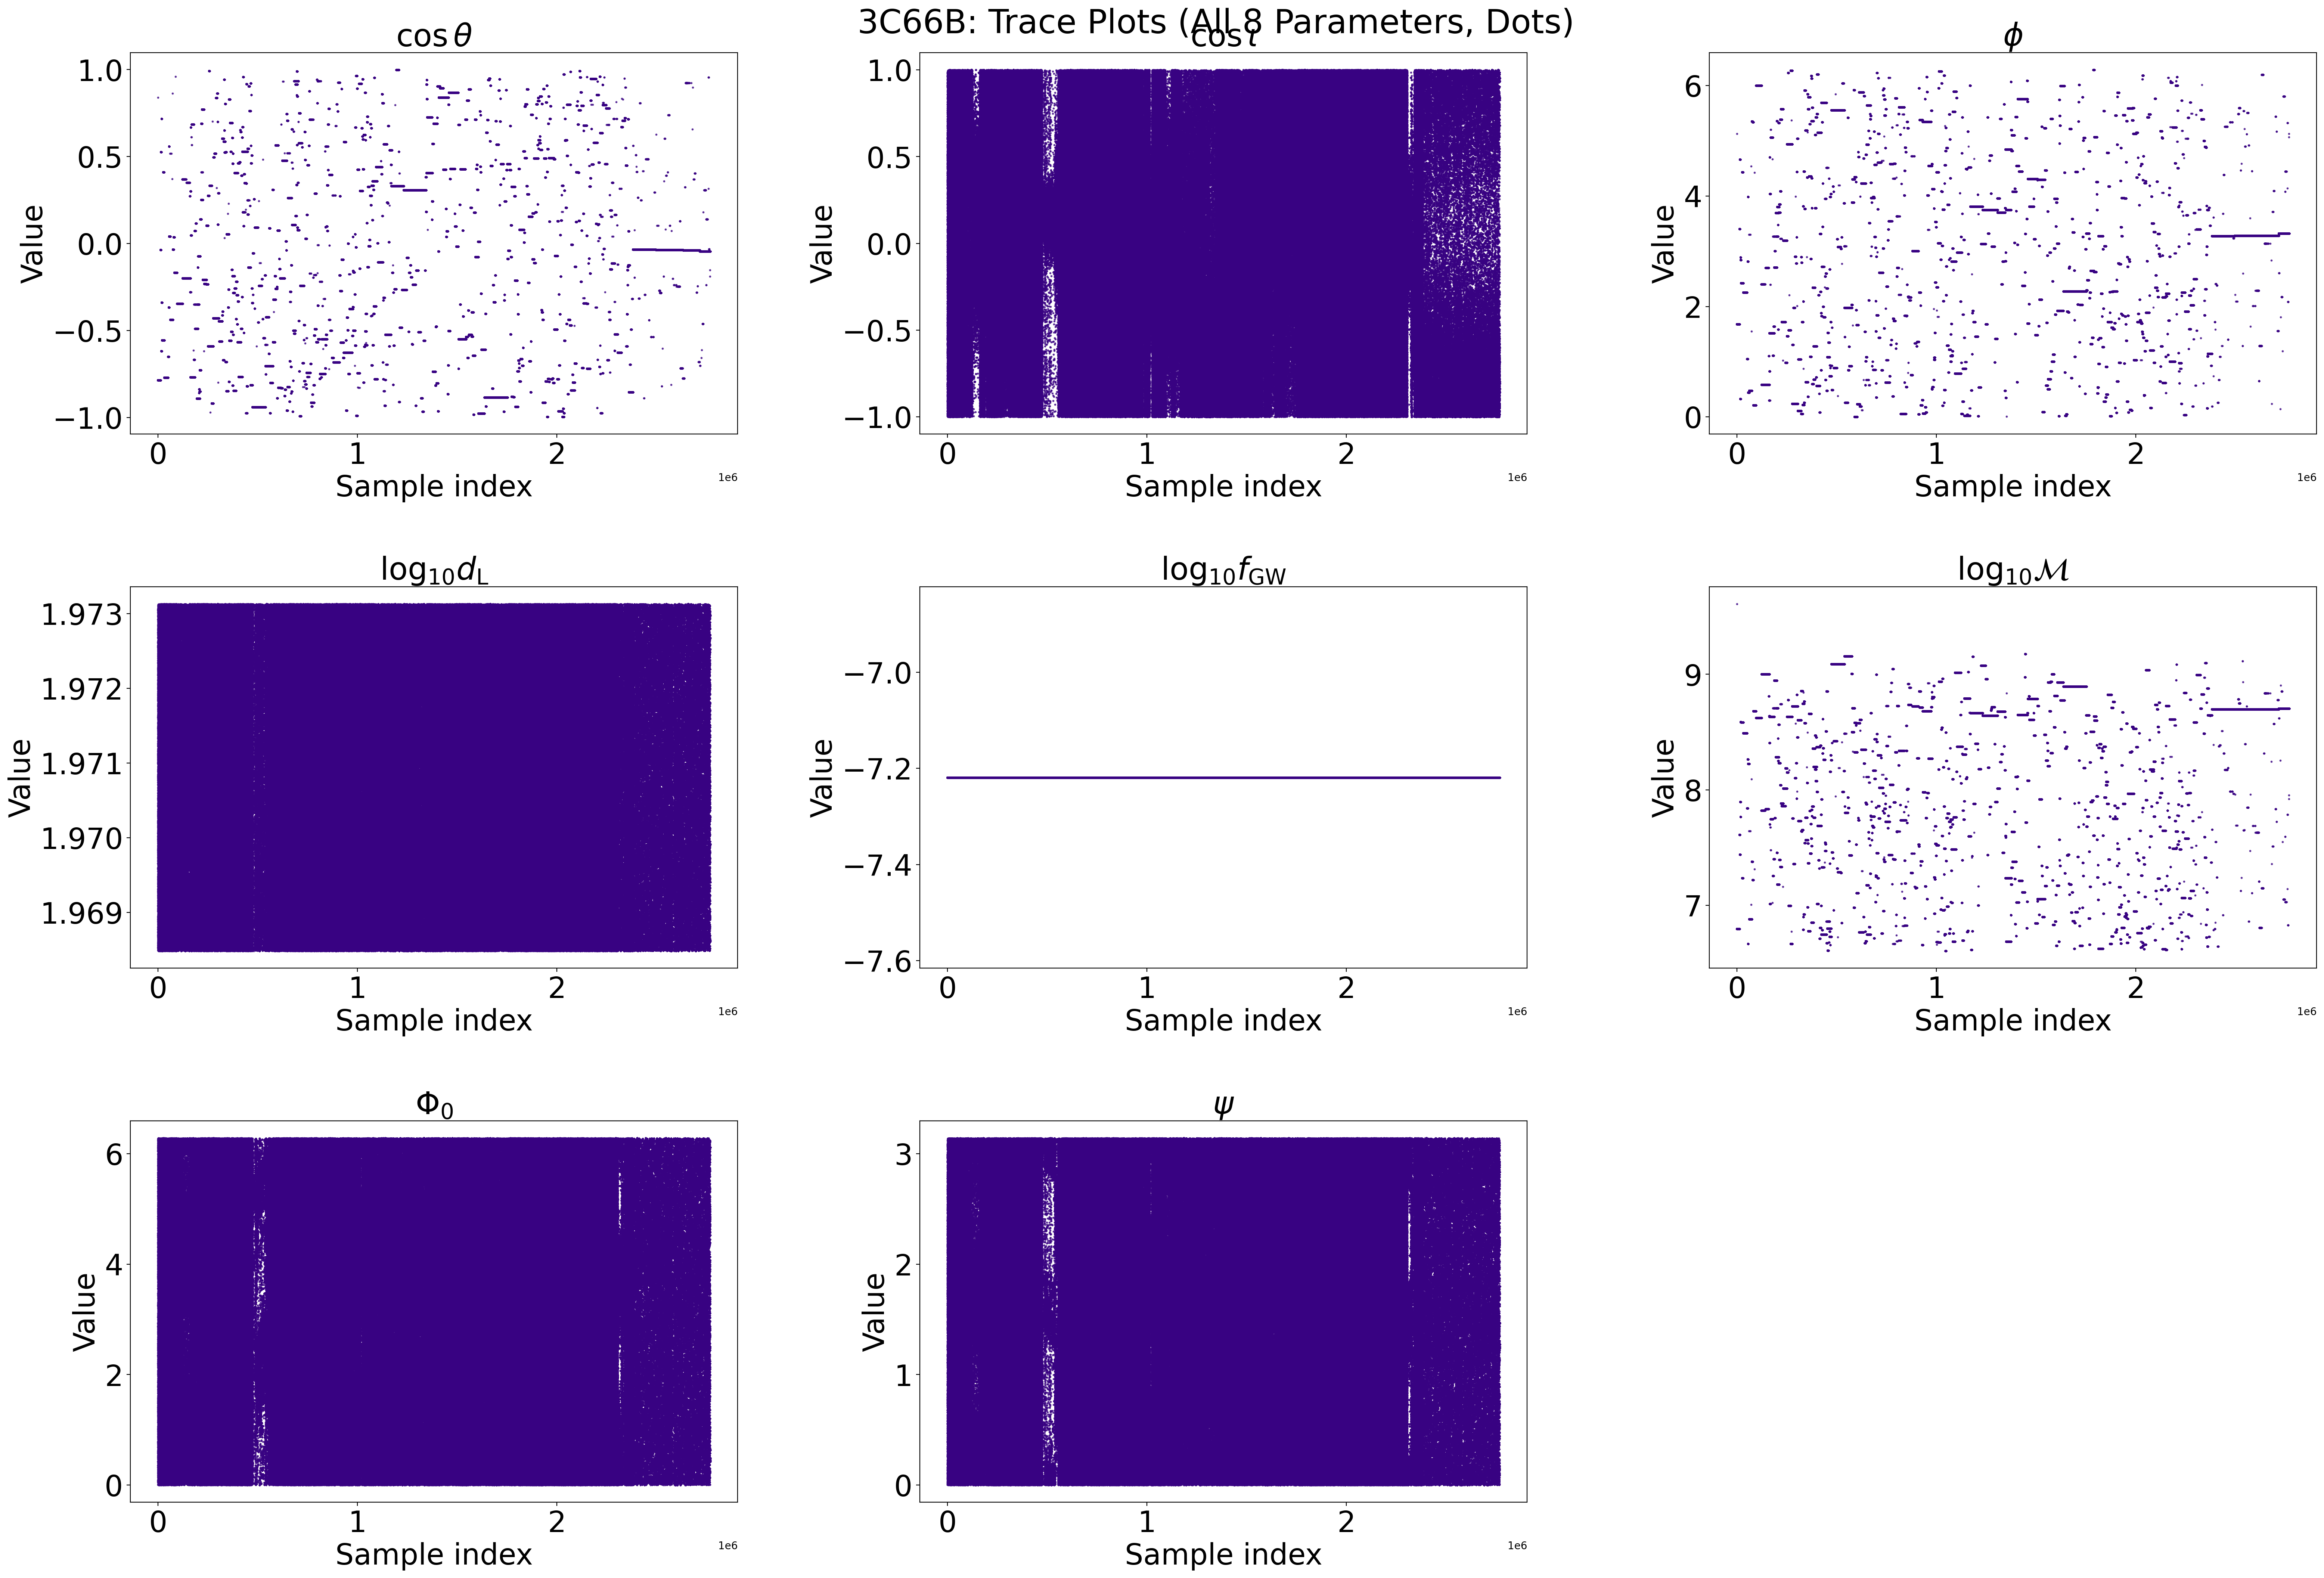

In [23]:
# Parameter titles (8 total)
titles = [
    r"$\cos \theta$",
    r"$\cos \iota$",
    r"$\phi$",
    r"$\log_{10} d_{\rm L}$",
    r"$\log_{10} f_{\rm GW}$",
    r"$\log_{10} {\cal M}$",
    r"$\Phi_0$",
    r"$\psi$"
]

# --- Layout settings ---
n_params = len(titles)
rows, cols = 3, 3   # 3×3 grid; last panel unused
fig, axs = plt.subplots(rows, cols, figsize=(30, 20))
axs = axs.flatten()
fig.tight_layout(h_pad=3, w_pad=2)

# --- Plot each parameter trace as dots ---
for i in range(n_params):
    axs[i].scatter(
        np.arange(samples_cold[0].shape[0]), 
        samples_cold[0][:, i],
        s=1.2,                # dot size (smaller = finer)
        color="xkcd:indigo",
        alpha=0.7
    )
    axs[i].set_title(titles[i], fontsize=30)
    axs[i].tick_params(axis="both", labelsize=28)
    axs[i].set_xlabel("Sample index", fontsize=28)
    axs[i].set_ylabel("Value", fontsize=28)

# --- Hide unused subplot (bottom right) ---
for j in range(n_params, rows * cols):
    axs[j].axis("off")

# --- Global title ---
fig.suptitle("3C66B: Trace Plots (All 8 Parameters, Dots)", fontsize=32, y=1.02)

plt.subplots_adjust(hspace=0.4, wspace=0.3)
# plt.show()
# plt.savefig("trace_plots_3C66B_all8_dots.png", dpi=200, bbox_inches="tight")


## SD BF

In [15]:
import numpy as np
from enterprise_extensions import model_utils

# -------------------- Physical constants -------------------- #
c = 2.99792458e8                  # m/s
T_sun = 1.327124400e20 / c**3     # G*M_sun / c^3 [s]
Mpc_to_m = 3.085677581e22         # 1 Mpc in meters

# -------------------- Extract parameters -------------------- #
# samples_cold[0] has shape (n_iter, n_params)
# columns: [cos_theta, cos_inc, phi, log10_dL, log10_fGW, log10_Mc, phase0, psi]
log10_dL = samples[:, 3]
log10_fGW = samples[:, 4]
log10_Mc  = samples[:, 5]

# Convert to linear units
dL_m = 10**log10_dL * Mpc_to_m   # convert Mpc → meters
fGW  = 10**log10_fGW             # Hz
Mc   = 10**log10_Mc              # M_sun

# -------------------- Compute strain amplitude -------------------- #
# h = 2 (M_c T_⊙)^(5/3) (π f_GW)^(2/3) * c / d_L
h_amp = 2 * (Mc * T_sun)**(5/3) * (np.pi * fGW)**(2/3) * c / dL_m
log10_h = np.log10(h_amp)

print(f"Derived strain amplitude range: {np.min(log10_h):.3f} to {np.max(log10_h):.3f}")

# -------------------- Savage–Dickey Bayes Factor -------------------- #
BF, BF_err = model_utils.bayes_fac(samples=log10_h, logAmin=-18, logAmax=-11)
print(f"Savage–Dickey BF on strain amplitude: {BF:.4f} ± {BF_err:.4f}")


Derived strain amplitude range: -31.307 to -19.458
Savage–Dickey BF on strain amplitude: 0.0079 ± 0.0037


In [21]:
# -------------------- Inspect parameter ranges -------------------- #
log10_dL = samples[:, 3]
log10_fGW = samples[:, 4]
log10_Mc  = samples[:, 5]

def summary_stats(name, arr):
    print(f"{name:12s} | min = {np.min(arr):.4f}, max = {np.max(arr):.4f}, "
          f"median = {np.median(arr):.4f}, "
          f"16–84% = [{np.percentile(arr,16):.4f}, {np.percentile(arr,84):.4f}]")

summary_stats("log10_dL", log10_dL)
summary_stats("log10_fGW", log10_fGW)
summary_stats("log10_Mc",  log10_Mc)


log10_dL     | min = 4043941.2500, max = 4052163840.0000, median = 383648800.0000, 16–84% = [16416679.0000, 614273152.0000]
log10_fGW    | min = 0.0000, max = 6.2832, median = 3.1561, 16–84% = [1.0128, 5.2414]
log10_Mc     | min = 0.0000, max = 3.1416, median = 1.5800, 16–84% = [0.4947, 2.6588]


log10_dL     | min = 6.6068, max = 9.6077, median = 8.5839, 16–84% = [7.2153, 8.7884]
log10_fGW    | min = 0.0000, max = 6.2832, median = 3.1561, 16–84% = [1.0128, 5.2414]
log10_Mc     | min = 0.0000, max = 3.1416, median = 1.5800, 16–84% = [0.4947, 2.6588]
log10 h range: -31.3071  to  -19.4579
log10 h median: -25.6905
Savage–Dickey BF on strain amplitude: 0.0079 ± 0.0037


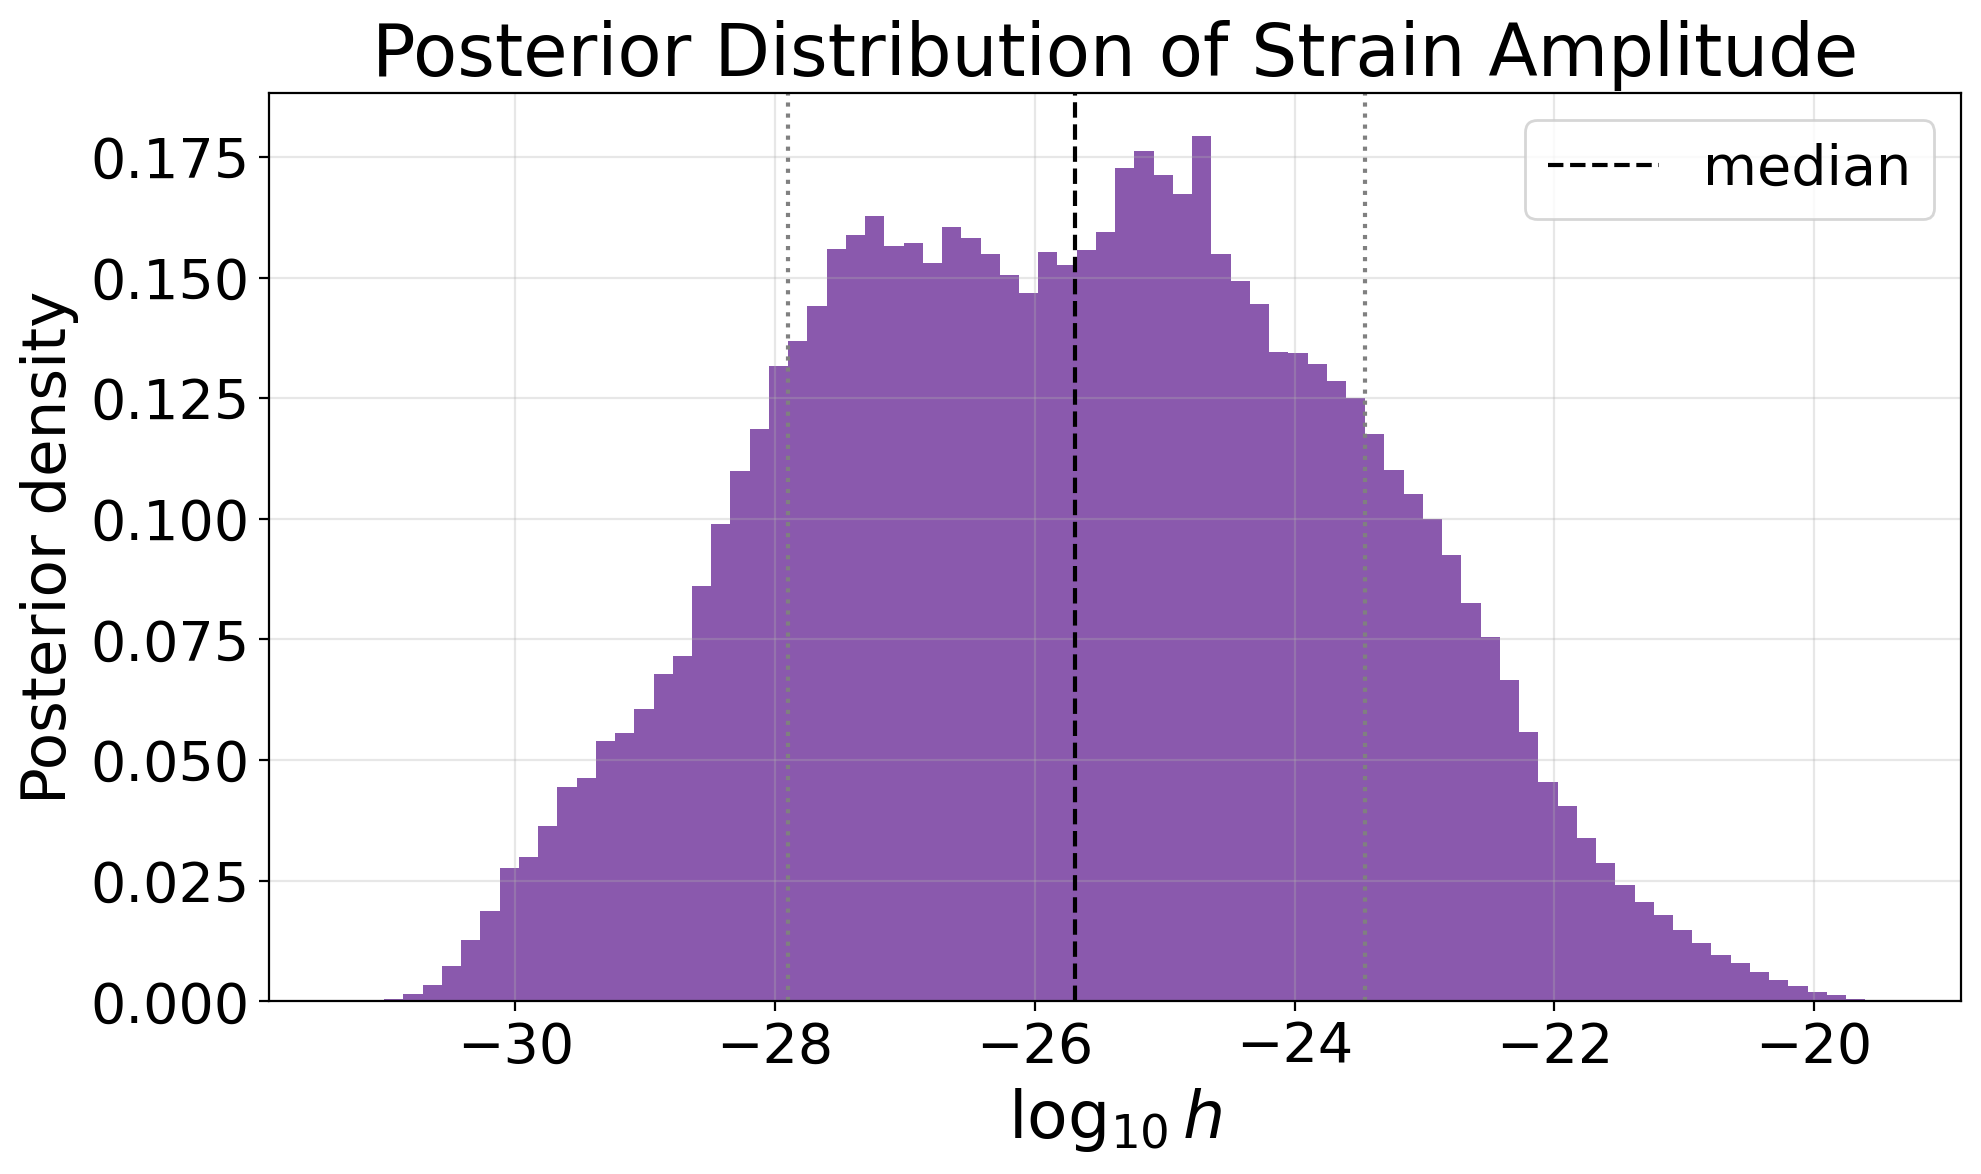

In [20]:
import matplotlib.pyplot as plt
import numpy as np
#from QuickCW import model_utils  # as before

# -------------------- Physical constants -------------------- #
c = 2.99792458e8                  # m/s
T_sun = 1.327124400e20 / c**3     # G*M_sun / c^3 [s]
Mpc_to_m = 3.085677581e22         # 1 Mpc in meters

# -------------------- Extract parameters -------------------- #
log10_dL = samples[:, 3]
log10_fGW = samples[:, 4]
log10_Mc  = samples[:, 5]

# Inspect ranges
def summary_stats(name, arr):
    print(f"{name:12s} | min = {np.min(arr):.4f}, max = {np.max(arr):.4f}, "
          f"median = {np.median(arr):.4f}, "
          f"16–84% = [{np.percentile(arr,16):.4f}, {np.percentile(arr,84):.4f}]")

summary_stats("log10_dL", log10_dL)
summary_stats("log10_fGW", log10_fGW)
summary_stats("log10_Mc",  log10_Mc)

# -------------------- Compute strain amplitude -------------------- #
dL_m = 10**log10_dL * Mpc_to_m
fGW  = 10**log10_fGW
Mc   = 10**log10_Mc

h_amp = 2 * (Mc * T_sun)**(5/3) * (np.pi * fGW)**(2/3) * c / dL_m
log10_h = np.log10(h_amp)

print(f"log10 h range: {np.min(log10_h):.4f}  to  {np.max(log10_h):.4f}")
print(f"log10 h median: {np.median(log10_h):.4f}")

# -------------------- Savage–Dickey Bayes Factor -------------------- #
BF, BF_err = model_utils.bayes_fac(samples=log10_h, logAmax=-11)
print(f"Savage–Dickey BF on strain amplitude: {BF:.4f} ± {BF_err:.4f}")

# -------------------- Posterior Histogram -------------------- #
plt.figure(figsize=(10,6))
n, bins, patches = plt.hist(
    log10_h, bins=80, density=True, color="#4B0082", alpha=0.65,
    histtype="stepfilled", linewidth=1.5
)
plt.axvline(np.median(log10_h), color="k", linestyle="--", label="median")
plt.axvline(np.percentile(log10_h, 16), color="gray", linestyle=":")
plt.axvline(np.percentile(log10_h, 84), color="gray", linestyle=":")
plt.xlabel(r"$\log_{10}\,h$", fontsize=24)
plt.ylabel("Posterior density", fontsize=22)
plt.title("Posterior Distribution of Strain Amplitude", fontsize=26)
plt.legend(fontsize=20)
plt.tick_params(axis="both", labelsize=20)
plt.grid(alpha=0.3)
plt.tight_layout()
# plt.show()
# plt.savefig("posterior_log10h.png", dpi=250, bbox_inches="tight")


In [ ]:
#d_L correlated SD BF
logamins = np.linspace(logAmin_dL, -15, 100)
BF_arr = []
BF_err_arr = []

from enterprise_extensions import model_utils
for logamin in logamins:
    BF,BF_err = model_utils.bayes_fac(samples = samples2plot[d_L_mask,4], logAmin=logamin, logAmax=-11)
    BF_arr.append(BF)
    BF_err_arr.append(BF_err)

plt.errorbar(logamins, BF_arr, yerr=BF_err_arr, fmt='o')
plt.xlabel('logAmin')
plt.ylabel("log10(BF)")
plt.title(BFerr_title)
plt.show()

In [ ]:
#d_L correlated SD BF
BF, BF_err = model_utils.bayes_fac(samples=samples2plot[d_L_mask,4], logAmax=-11)
print(f"log10A BF = {BF:.4f} ± {BF_err:.4f}")

In [ ]:
#Non d_L correlated SD BF
from enterprise_extensions import model_utils
BF,BF_err = model_utils.bayes_fac(samples = samples_cold[0][::10,4], logAmax=-11)
print(f"log10A BF = {BF:.4f} ± {BF_err:.4f}")

In [ ]:
print(BF_arr[0:10])

In [ ]:
print(BF_err_arr[0:10])